<a href="https://colab.research.google.com/github/MAI-AIIU/deep-learning/blob/main/src/fifth-week/softmax-regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Softmax Regression

# Softmax Regression from Scratch with PyTorch
:label:`sec_softmax_scratch`

This notebook builds a multiclass classifier without helper packages such as `d2l`. We will implement the softmax operation and inspect cross-entropy, then use PyTorch tensors, autograd, modules, optimizers, and data loaders to train and evaluate the model on Fashion-MNIST.

In [1]:
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

random.seed(0)
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## The Softmax

Softmax converts one score per class into a probability distribution. For a batch of examples, rows correspond to examples and columns to classes. We normalize across each row so its probabilities sum to one.

In [2]:
X = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
X.sum(), X.sum(dim=0, keepdim=True), X.sum(dim=1, keepdim=True)

(tensor(21.),
 tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

For each row $i$ and class $j$, softmax is

$$\mathrm{softmax}(\mathbf{X})_{ij} = \frac{\exp(\mathbf{X}_{ij})}{\sum_k \exp(\mathbf{X}_{ik})}.$$

A direct exponentiation can overflow for large scores. Subtracting each row's maximum before exponentiation leaves the probabilities unchanged and keeps the exponentials bounded.

In [3]:
def softmax(scores):
    shifted_scores = scores - scores.max(dim=1, keepdim=True).values
    exp_scores = torch.exp(shifted_scores)
    return exp_scores / exp_scores.sum(dim=1, keepdim=True)

Each output is nonnegative, and each row sums to one. PyTorch also provides a stable implementation, `torch.softmax`; the hand-written function here is for understanding the operation, not as the preferred production implementation.

In [4]:
scores = torch.tensor([[0.2, 1.0, -0.5, 0.3, 0.7], [1000.0, 999.0, 998.0, 997.0, 996.0]])
probabilities = softmax(scores)
probabilities, probabilities.sum(dim=1), torch.softmax(scores, dim=1)

(tensor([[0.1544, 0.3437, 0.0767, 0.1707, 0.2546],
         [0.6364, 0.2341, 0.0861, 0.0317, 0.0117]]),
 tensor([1.0000, 1.0000]),
 tensor([[0.1544, 0.3437, 0.0767, 0.1707, 0.2546],
         [0.6364, 0.2341, 0.0861, 0.0317, 0.0117]]))

## The Model

Fashion-MNIST images are grayscale arrays of shape $28 \times 28$. Flattening each image gives 784 input features. The model computes 10 class scores, one for each clothing category. We initialize the weights with small Gaussian noise and the bias with zeros.

In [5]:
class SoftmaxRegressionScratch(nn.Module):
    def __init__(self, num_inputs=28 * 28, num_classes=10, sigma=0.01):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(num_inputs, num_classes) * sigma)
        self.bias = nn.Parameter(torch.zeros(num_classes))

    def forward(self, images):
        flattened_images = images.reshape(images.shape[0], -1)
        return flattened_images @ self.weight + self.bias


model = SoftmaxRegressionScratch().to(device)
print(model)

SoftmaxRegressionScratch()


`forward` returns logits (unnormalized class scores). This is intentional: PyTorch's cross-entropy loss combines log-softmax and negative log-likelihood in a numerically stable operation.

In [6]:
sample_images = torch.rand(4, 1, 28, 28, device=device)
logits = model(sample_images)
logits.shape, torch.softmax(logits, dim=1).sum(dim=1)

(torch.Size([4, 10]),
 tensor([1.0000, 1.0000, 1.0000, 1.0000], device='cuda:0',
        grad_fn=<SumBackward1>))

## Cross-Entropy Loss

For a labeled example, cross-entropy is the negative logarithm of the probability assigned to its correct class. With integer class labels, we can select those probabilities directly. In training, however, we pass logits to `torch.nn.functional.cross_entropy`, which is more numerically stable than taking the logarithm of softmax probabilities ourselves.

In [7]:
labels = torch.tensor([0, 2])
predicted_probabilities = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])
selected_probabilities = predicted_probabilities[torch.arange(labels.shape[0]), labels]
selected_probabilities

tensor([0.1000, 0.5000])

The direct formula is useful for understanding the objective. Clamp probabilities away from zero to avoid `log(0)`; for model training prefer PyTorch's stable logits-based loss.

In [8]:
def cross_entropy_from_probabilities(probabilities, targets):
    chosen = probabilities[torch.arange(targets.shape[0], device=targets.device), targets]
    return -torch.log(chosen.clamp_min(torch.finfo(chosen.dtype).tiny)).mean()


example_loss = cross_entropy_from_probabilities(predicted_probabilities, labels)
framework_loss = F.cross_entropy(torch.log(predicted_probabilities), labels)
example_loss, framework_loss

(tensor(1.4979), tensor(1.4979))

In [9]:
# Cross-entropy consumes logits directly and applies the stable log-softmax internally.
F.cross_entropy(torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]]), labels)

tensor(1.1466)

## Training

We will download Fashion-MNIST through `torchvision`, create shuffled minibatches, and train for 10 epochs. The test split is used here for tracking evaluation performance, as in the original lesson. Adjust `batch_size`, `learning_rate`, and `num_epochs` to experiment.

In [10]:
batch_size = 256
learning_rate = 0.1
num_epochs = 5

transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root="../data", train=True, transform=transform, download=True)
test_dataset = datasets.FashionMNIST(root="../data", train=False, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

class_names = train_dataset.classes
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)


def evaluate(data_loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for images, targets in data_loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += F.cross_entropy(logits, targets, reduction="sum").item()
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.shape[0]
    return total_loss / total_examples, total_correct / total_examples


history = {"train_loss": [], "test_loss": [], "test_accuracy": []}
for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0.0
    total_train_examples = 0
    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, targets)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * targets.shape[0]
        total_train_examples += targets.shape[0]

    train_loss = total_train_loss / total_train_examples
    test_loss, test_accuracy = evaluate(test_loader)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_accuracy)
    print(
        f"Epoch {epoch + 1:2d}/{num_epochs} | "
        f"train loss {train_loss:.4f} | test loss {test_loss:.4f} | "
        f"test accuracy {test_accuracy:.2%}"
    )

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 162kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.9MB/s]


Epoch  1/5 | train loss 0.7843 | test loss 0.6358 | test accuracy 78.21%
Epoch  2/5 | train loss 0.5712 | test loss 0.5637 | test accuracy 81.08%
Epoch  3/5 | train loss 0.5252 | test loss 0.5368 | test accuracy 82.04%
Epoch  4/5 | train loss 0.5008 | test loss 0.5430 | test accuracy 81.02%
Epoch  5/5 | train loss 0.4852 | test loss 0.5110 | test accuracy 82.63%


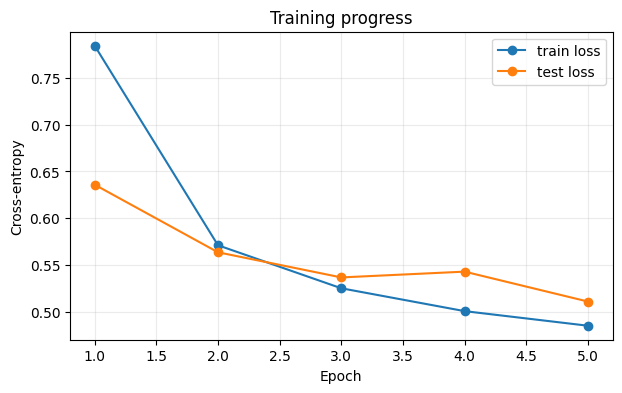

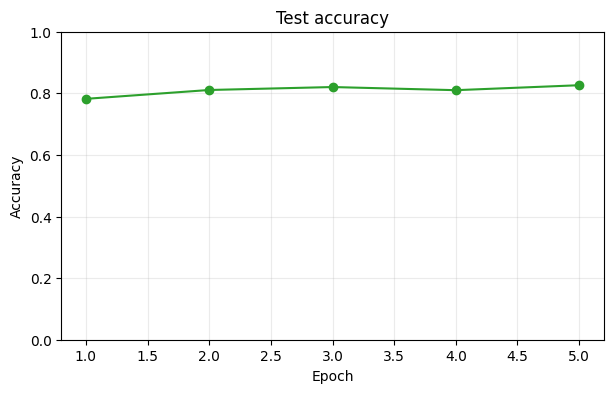

In [11]:
epochs = range(1, num_epochs + 1)
fig, loss_axis = plt.subplots(figsize=(7, 4))
loss_axis.plot(epochs, history["train_loss"], marker="o", label="train loss")
loss_axis.plot(epochs, history["test_loss"], marker="o", label="test loss")
loss_axis.set(xlabel="Epoch", ylabel="Cross-entropy", title="Training progress")
loss_axis.legend()
loss_axis.grid(alpha=0.25)
plt.show()

fig, accuracy_axis = plt.subplots(figsize=(7, 4))
accuracy_axis.plot(epochs, history["test_accuracy"], marker="o", color="tab:green")
accuracy_axis.set(xlabel="Epoch", ylabel="Accuracy", title="Test accuracy", ylim=(0, 1))
accuracy_axis.grid(alpha=0.25)
plt.show()

## Prediction

After training, use the model's largest logit to select the predicted class. Softmax is unnecessary for choosing the most likely class because it preserves the ordering of logits.

In [12]:
model.eval()
images, targets = next(iter(test_loader))
with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()
predictions.shape, targets.shape

(torch.Size([256]), torch.Size([256]))

We can inspect mistakes by plotting test images with their true and predicted labels.

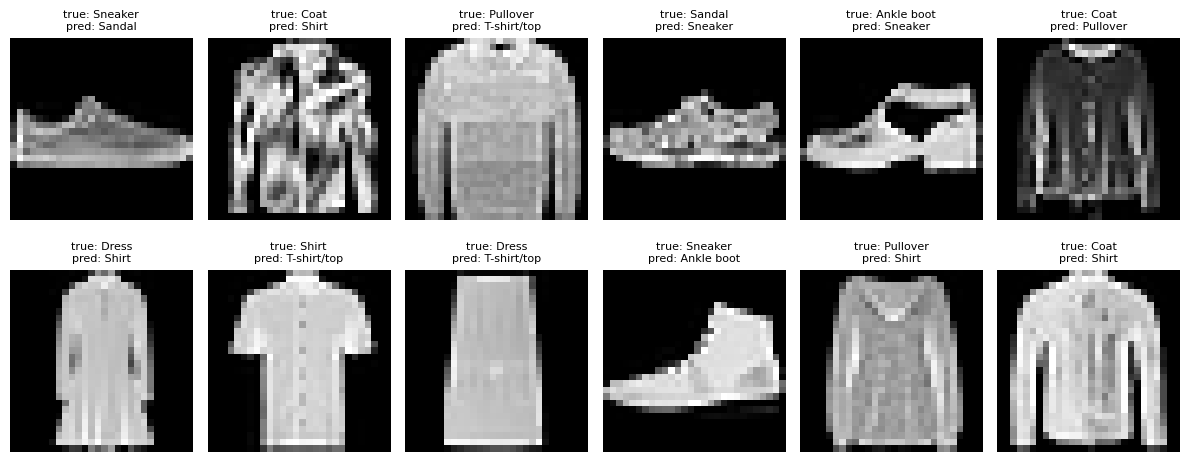

In [13]:
incorrect_indices = (predictions != targets).nonzero(as_tuple=True)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for axis, index in zip(axes.flat, incorrect_indices):
    axis.imshow(images[index].squeeze(0), cmap="gray")
    axis.set_title(
        f"true: {class_names[targets[index]]}\npred: {class_names[predictions[index]]}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(incorrect_indices):]:
    axis.axis("off")
plt.tight_layout()
plt.show()

## Summary

We implemented a numerically stable softmax, built a linear classifier with PyTorch, and trained it using autograd, minibatches, and SGD. The hand-written model makes the mechanics visible; the built-in `torch.nn.Linear` and `torch.nn.CrossEntropyLoss` are convenient alternatives for regular model development.

## Exercises

1. Compare the custom `softmax` with `torch.softmax` on scores containing very large positive and negative values. Why does subtracting the row maximum help?
<!-- 1. Implement cross-entropy using one-hot labels and compare its result and execution speed with `F.cross_entropy`.
1. Is it always appropriate to return the most likely label? What additional information could help in a high-stakes application such as medical diagnosis?
1. What challenges arise when the number of classes is extremely large, as with next-word prediction over a large vocabulary?
1. Plot the training and test losses in `history`. Experiment with learning rates and minibatch sizes, changing one parameter at a time.

**Setup:** The notebook requires PyTorch, torchvision, and matplotlib. Fashion-MNIST is downloaded to the `data` directory on first use. -->

# Solution

In [18]:
def softmax_without_subtracting_the_max(scores):
    exp_scores = torch.exp(scores)
    return exp_scores / exp_scores.sum(dim=1, keepdim=True)

In [20]:
import torch

scores = torch.tensor([
    [1000.0, 1001.0, 1002.0],     # Large positive values
    [-1000.0, -1001.0, -1002.0],  # Large negative values
])

# below softmax function is called from cells above
custom_result = softmax(scores)
torch_result = torch.softmax(scores, dim=1)

# Direct exponentiation, to demonstrate the numerical problem
naive_result = softmax_without_subtracting_the_max(scores)

print("Input scores:\n", scores)
print("\nCustom softmax:\n", custom_result)
print("\nPyTorch softmax:\n", torch_result)
print("\nWithout subtracting the maximum:\n", naive_result)

print("\nCustom row sums:", custom_result.sum(dim=1))
print("PyTorch row sums:", torch_result.sum(dim=1))

Input scores:
 tensor([[ 1000.,  1001.,  1002.],
        [-1000., -1001., -1002.]])

Custom softmax:
 tensor([[0.0900, 0.2447, 0.6652],
        [0.6652, 0.2447, 0.0900]])

PyTorch softmax:
 tensor([[0.0900, 0.2447, 0.6652],
        [0.6652, 0.2447, 0.0900]])

Without subtracting the maximum:
 tensor([[nan, nan, nan],
        [nan, nan, nan]])

Custom row sums: tensor([1., 1.])
PyTorch row sums: tensor([1., 1.])


Note:  
1: both custom softmax and the torch built-in softmax produces the same result both for larger and negative numbers.  
2: using softmax without subtracting from max number results NaN, cause its response is inf/inf which results NaN
